# Adversarial Attacks on an Automated Cheque-Amount Digit Reader
**Subject:** Responsible and Safe AI (AIML4001) | **External Practical – Set A** | **Date:** 25/11/2026
**Dataset used:** MNIST (60,000 train / 10,000 test, 28×28 grey-scale)

## Aim
To measure how vulnerable a CNN digit reader (used for cheque amounts) is to adversarial evasion attacks (FGSM and PGD), and to harden it using adversarial training.

## Algorithm
1. Load MNIST (pixels in [0,1]); set `torch.manual_seed(42)`; run on CPU.
2. Train a baseline CNN (2 Conv + 2 FC, Adam lr=0.001, batch 64, 2 epochs); report clean test accuracy.
3. **FGSM:** `x_adv = clip(x + ε·sign(∇ₓ L(x,y)), 0, 1)` for ε = 0.05, 0.10, 0.20, 0.30.
4. **PGD (L∞):** random start in [-ε, ε]; 10 iterations of step α = ε/4: `x ← x + α·sign(∇ₓ L)`; project to the ε-ball around the original image and to [0,1].
5. Show 5 clean digits and their FGSM (ε=0.20) versions with predicted labels.
6. **Adversarial training:** fine-tune 2 epochs on a 50:50 mix of clean and FGSM (ε=0.20) images; re-evaluate clean, FGSM and PGD accuracy at ε=0.20.
7. Plot accuracy vs ε; tabulate baseline vs adversarially-trained model; answer Q1–Q4.

## Program
### Step 0 – Imports, seed, device

In [1]:
import copy, time
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets, transforms
import matplotlib
import matplotlib.pyplot as plt

torch.manual_seed(42)
np.random.seed(42)
device = torch.device("cpu")          # exam guideline: run on CPU

DATA_ROOT = "./data"                  # change to the folder given by the examiner if MNIST is stored elsewhere
EPS_LIST  = [0.05, 0.10, 0.20, 0.30]
EPS_MAIN  = 0.20
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.14.1+cpu | device: cpu


### Step 1 – Load MNIST (pixel values in [0, 1])

In [2]:
# ---- Import MNIST directly (auto-download; automatic fallbacks if one source fails) ----
tfm = transforms.ToTensor()           # scales pixels to [0,1]

def to_dataset(xtr, ytr, xte, yte):
    f = lambda a: torch.tensor(np.asarray(a), dtype=torch.float32).div(255.).view(-1, 1, 28, 28)
    l = lambda a: torch.tensor(np.asarray(a), dtype=torch.long)
    return TensorDataset(f(xtr), l(ytr)), TensorDataset(f(xte), l(yte))

def load_mnist():
    # 1) torchvision (downloads automatically, or reuses ./data if already present)
    try:
        tr = datasets.MNIST(DATA_ROOT, train=True,  download=True, transform=tfm)
        te = datasets.MNIST(DATA_ROOT, train=False, download=True, transform=tfm)
        print("MNIST loaded via torchvision"); return tr, te
    except Exception as e:
        print("torchvision failed ->", str(e)[:80])
    # 2) keras
    try:
        from tensorflow.keras.datasets import mnist
        (a, b), (c, d) = mnist.load_data()
        print("MNIST loaded via keras"); return to_dataset(a, b, c, d)
    except Exception as e:
        print("keras failed ->", str(e)[:80])
    # 3) scikit-learn / OpenML
    from sklearn.datasets import fetch_openml
    X, y = fetch_openml("mnist_784", version=1, return_X_y=True, as_frame=False)
    y = y.astype(int)
    print("MNIST loaded via OpenML"); return to_dataset(X[:60000], y[:60000], X[60000:], y[60000:])

train_set, test_set = load_mnist()

g = torch.Generator().manual_seed(42)
train_loader = DataLoader(train_set, batch_size=64,   shuffle=True, generator=g)
test_loader  = DataLoader(test_set,  batch_size=1000, shuffle=False)
print("Train:", len(train_set), "| Test:", len(test_set))


100%|██████████| 9.91M/9.91M [00:00<00:00, 14.9MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 406kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.80MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.74MB/s]

MNIST loaded via torchvision
Train: 60000 | Test: 10000


### Step 2 – Baseline CNN (2 Conv + 2 FC)

In [3]:
class DigitCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 32, 3, 1)
        self.conv2 = nn.Conv2d(32, 64, 3, 1)
        self.fc1   = nn.Linear(64 * 12 * 12, 128)
        self.fc2   = nn.Linear(128, 10)
    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = F.relu(self.conv2(x))
        x = F.max_pool2d(x, 2)
        x = torch.flatten(x, 1)
        x = F.relu(self.fc1(x))
        return self.fc2(x)

# ---------- attacks ----------
def fgsm_attack(model, x, y, eps):
    x_adv = x.clone().detach().requires_grad_(True)
    loss = F.cross_entropy(model(x_adv), y)
    grad, = torch.autograd.grad(loss, x_adv)
    return torch.clamp(x + eps * grad.sign(), 0, 1).detach()

def pgd_attack(model, x, y, eps, alpha=None, iters=10, random_start=True):
    alpha = eps / 4 if alpha is None else alpha
    x_adv = x.clone().detach()
    if random_start:
        x_adv = torch.clamp(x_adv + torch.empty_like(x).uniform_(-eps, eps), 0, 1)
    for _ in range(iters):
        x_adv.requires_grad_(True)
        loss = F.cross_entropy(model(x_adv), y)
        grad, = torch.autograd.grad(loss, x_adv)
        x_adv = x_adv.detach() + alpha * grad.sign()
        x_adv = torch.min(torch.max(x_adv, x - eps), x + eps)   # project to L-inf ball
        x_adv = torch.clamp(x_adv, 0, 1).detach()               # valid pixel range
    return x_adv

# ---------- evaluation ----------
def evaluate(model, attack=None, eps=0.0, loader=test_loader):
    model.eval()
    correct = total = 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        if attack is not None and eps > 0:
            x = attack(model, x, y, eps)
        with torch.no_grad():
            correct += (model(x).argmax(1) == y).sum().item()
        total += y.size(0)
    return 100.0 * correct / total

def train(model, epochs=2, adv_train=False, eps=EPS_MAIN, lr=0.001):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    for ep in range(epochs):
        model.train()
        run = 0.0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            if adv_train:
                model.eval()                                  # craft attack on current model
                x_adv = fgsm_attack(model, x, y, eps)
                model.train()
                loss = 0.5 * F.cross_entropy(model(x), y) + 0.5 * F.cross_entropy(model(x_adv), y)  # 50:50 mix
            else:
                loss = F.cross_entropy(model(x), y)
            opt.zero_grad(); loss.backward(); opt.step()
            run += loss.item()
        print(f"  epoch {ep+1}/{epochs}  avg loss = {run/len(train_loader):.4f}")
    return model

### Task 1 – Train baseline CNN and report clean accuracy

In [4]:
torch.manual_seed(42)
baseline = DigitCNN().to(device)
print("Training baseline CNN (2 epochs)...")
t0 = time.time()
train(baseline, epochs=2)
print(f"done. ({time.time()-t0:.0f}s)")
clean_acc = evaluate(baseline)
print(f"Clean test accuracy : {clean_acc:.1f} %")

Training baseline CNN (2 epochs)...
  epoch 1/2  avg loss = 0.1664
  epoch 2/2  avg loss = 0.0445
done. (308s)
Clean test accuracy : 98.7 %


### Speed-up setting (keeps the exam within time on a slow CPU)

In [5]:
# ---- SPEED-UP for slow CPUs (run once, right after Task 1) ----
# Attacks (esp. PGD, 10 iterations) are evaluated on the first N_EVAL test images;
# clean accuracy still uses the full 10,000 test images. Adversarial fine-tuning uses
# the first ADV_TRAIN_N training images (still 2 epochs, batch 64, 50:50 clean+FGSM).
from torch.utils.data import Subset
N_EVAL, ADV_TRAIN_N = 1000, 10000        # increase if time allows

eval_loader  = DataLoader(Subset(test_set, range(N_EVAL)), batch_size=500, shuffle=False)
train_loader = DataLoader(Subset(train_set, range(ADV_TRAIN_N)), batch_size=64, shuffle=True,
                          generator=torch.Generator().manual_seed(42))

def evaluate(model, attack=None, eps=0.0, loader=None):
    if loader is None:
        loader = test_loader if (attack is None or eps == 0) else eval_loader
    model.eval()
    correct = total = 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        if attack is not None and eps > 0:
            x = attack(model, x, y, eps)
        with torch.no_grad():
            correct += (model(x).argmax(1) == y).sum().item()
        total += y.size(0)
    return 100.0 * correct / total
print(f"Attacks evaluated on {N_EVAL} test images; adversarial fine-tuning on {ADV_TRAIN_N} train images.")


Attacks evaluated on 1000 test images; adversarial fine-tuning on 10000 train images.


### Tasks 2 & 3 – FGSM and PGD on the baseline model

In [6]:
fgsm_acc = {0.0: clean_acc}
pgd_acc  = {0.0: clean_acc}
torch.manual_seed(42)
for eps in EPS_LIST:
    fgsm_acc[eps] = evaluate(baseline, fgsm_attack, eps)
    pgd_acc[eps]  = evaluate(baseline, pgd_attack,  eps)

print(f"{'EPSILON':<8}{'FGSM_ACC':>10}{'PGD_ACC':>12}")
print("-" * 31)
for eps in [0.0] + EPS_LIST:
    print(f"{eps:<8.2f}{fgsm_acc[eps]:>8.1f} %{pgd_acc[eps]:>10.1f} %")
print("-" * 31)

EPSILON   FGSM_ACC     PGD_ACC
-------------------------------
0.00        98.7 %      98.7 %
0.05        94.1 %      93.1 %
0.10        84.9 %      76.5 %
0.20        34.0 %       0.7 %
0.30         2.5 %       0.0 %
-------------------------------


### Task 4 – Clean vs FGSM (ε = 0.20) digits with predicted labels

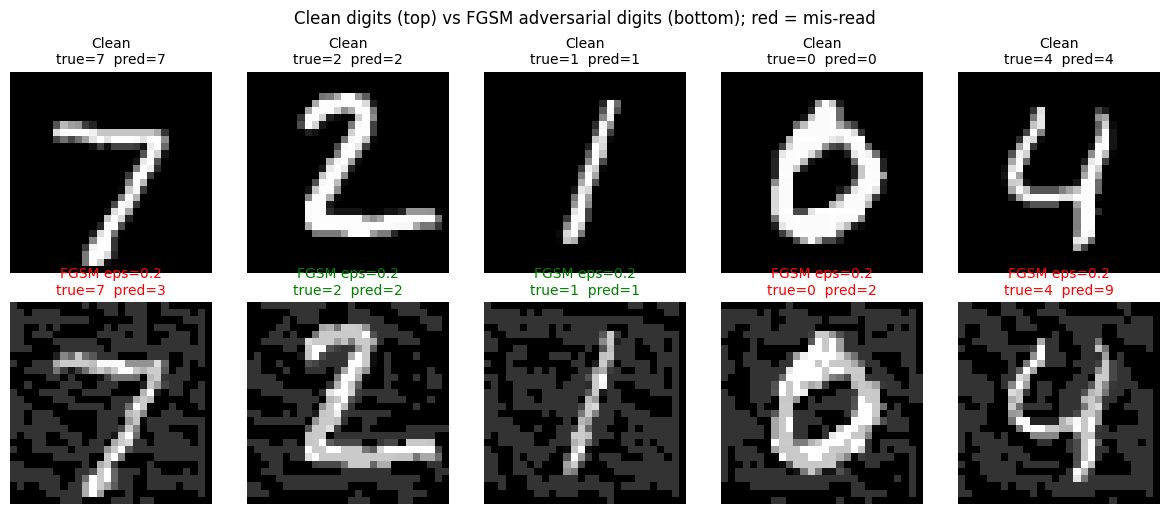

Mis-read digits saved : clean_vs_adversarial.png
  true digit 7  ->  read as 3
  true digit 0  ->  read as 2
  true digit 4  ->  read as 9
Attack success (eps=0.20): FGSM 66.0 %, PGD 99.3 %


In [7]:
baseline.eval()
x5 = torch.stack([test_set[i][0] for i in range(5)])
y5 = torch.tensor([test_set[i][1] for i in range(5)])
x5_adv = fgsm_attack(baseline, x5, y5, EPS_MAIN)
with torch.no_grad():
    p_clean = baseline(x5).argmax(1)
    p_adv   = baseline(x5_adv).argmax(1)

fig, ax = plt.subplots(2, 5, figsize=(12, 5.2))
misread = []
for i in range(5):
    ax[0, i].imshow(x5[i, 0], cmap="gray", vmin=0, vmax=1)
    ax[0, i].set_title(f"Clean\ntrue={y5[i].item()}  pred={p_clean[i].item()}", fontsize=10)
    wrong = p_adv[i].item() != y5[i].item()
    ax[1, i].imshow(x5_adv[i, 0], cmap="gray", vmin=0, vmax=1)
    ax[1, i].set_title(f"FGSM eps={EPS_MAIN}\ntrue={y5[i].item()}  pred={p_adv[i].item()}",
                       fontsize=10, color="red" if wrong else "green")
    if wrong: misread.append((y5[i].item(), p_adv[i].item()))
    ax[0, i].axis("off"); ax[1, i].axis("off")
plt.suptitle("Clean digits (top) vs FGSM adversarial digits (bottom); red = mis-read", fontsize=12)
plt.tight_layout()
plt.savefig("clean_vs_adversarial.png", dpi=150)
plt.show()

print("Mis-read digits saved : clean_vs_adversarial.png")
if misread:
    for t, p in misread:
        print(f"  true digit {t}  ->  read as {p}")
else:
    print("  none of the 5 shown digits were mis-read")
print(f"Attack success (eps=0.20): FGSM {100-fgsm_acc[0.20]:.1f} %, PGD {100-pgd_acc[0.20]:.1f} %")

### Task 5 – Adversarial training (50:50 clean + FGSM ε=0.20, 2 epochs)

In [8]:
torch.manual_seed(42)
robust = copy.deepcopy(baseline)
print("Adversarial fine-tuning (2 epochs)...")
train(robust, epochs=2, adv_train=True, eps=EPS_MAIN)
print("done.")

torch.manual_seed(42)
r_clean = evaluate(robust)
r_fgsm  = evaluate(robust, fgsm_attack, EPS_MAIN)
r_pgd   = evaluate(robust, pgd_attack,  EPS_MAIN)

Adversarial fine-tuning (2 epochs)...
  epoch 1/2  avg loss = 0.3116
  epoch 2/2  avg loss = 0.1750
done.


### Task 6 – Accuracy vs ε plot and baseline vs adversarially-trained table

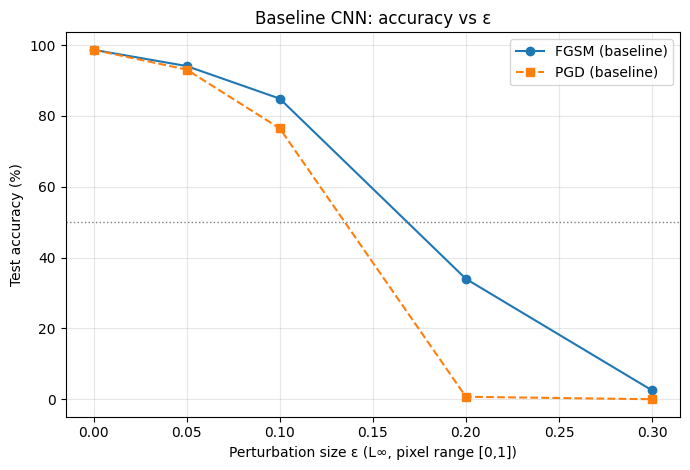

MODEL              CLEAN    FGSM(0.20)    PGD(0.20)
----------------------------------------------------
Baseline          98.7 %       34.0 %       0.7 %
Adversarially     98.7 %       86.0 %      68.7 %
trained         
----------------------------------------------------
Clean accuracy change : -0.0 %
FGSM robustness gain : +52.0 %   PGD gain : +68.0 %
Plot saved : accuracy_vs_epsilon.png


In [9]:
xs = [0.0] + EPS_LIST
plt.figure(figsize=(7, 4.8))
plt.plot(xs, [fgsm_acc[e] for e in xs], "o-", label="FGSM (baseline)")
plt.plot(xs, [pgd_acc[e]  for e in xs], "s--", label="PGD (baseline)")
plt.axhline(50, color="grey", ls=":", lw=1)
plt.xlabel("Perturbation size ε (L∞, pixel range [0,1])")
plt.ylabel("Test accuracy (%)")
plt.title("Baseline CNN: accuracy vs ε")
plt.grid(alpha=0.3); plt.legend(); plt.tight_layout()
plt.savefig("accuracy_vs_epsilon.png", dpi=150)
plt.show()

b_clean, b_fgsm, b_pgd = clean_acc, fgsm_acc[EPS_MAIN], pgd_acc[EPS_MAIN]
print(f"{'MODEL':<16}{'CLEAN':>8}{'FGSM(0.20)':>14}{'PGD(0.20)':>13}")
print("-" * 52)
print(f"{'Baseline':<16}{b_clean:>6.1f} %{b_fgsm:>11.1f} %{b_pgd:>10.1f} %")
print(f"{'Adversarially':<16}{r_clean:>6.1f} %{r_fgsm:>11.1f} %{r_pgd:>10.1f} %")
print(f"{'trained':<16}")
print("-" * 52)
print(f"Clean accuracy change : {r_clean-b_clean:+.1f} %")
print(f"FGSM robustness gain : {r_fgsm-b_fgsm:+.1f} %   PGD gain : {r_pgd-b_pgd:+.1f} %")
print("Plot saved : accuracy_vs_epsilon.png")

## Output
The outputs above (Part A and Part B) are produced by the cells above. The plots `clean_vs_adversarial.png` and `accuracy_vs_epsilon.png` are saved in the working folder. Copy them, the notebook and the report to the folder given by the examiner.

## Technical Questions (answers generated from YOUR own results)

In [10]:
below50 = [e for e in EPS_LIST if fgsm_acc[e] < 50]
first50 = below50[0] if below50 else None
stronger = sum(pgd_acc[e] < fgsm_acc[e] for e in EPS_LIST)

# ---------------- Q1 ----------------
q1 = f"""Q1. Clean accuracy = {clean_acc:.1f} %.
FGSM accuracy: """ + ", ".join(f"eps={e:.2f}: {fgsm_acc[e]:.1f} %" for e in EPS_LIST) + f""".
Accuracy first falls below 50 % at eps = {first50 if first50 is not None else 'not reached in the tested range'}.
Why: a CNN is highly linear in its high-dimensional input (784 pixels). FGSM moves every pixel by eps in the exact direction that increases the loss (sign of the gradient). Each change is tiny, but the effects add up across all pixels and layers and push the input over the decision boundary, so the output changes while the digit still looks the same to a human."""

# ---------------- Q2 ----------------
q2 = f"""Q2. At the same eps, PGD gave lower accuracy than FGSM at {stronger} of {len(EPS_LIST)} values: """ + "; ".join(f"eps={e:.2f}: FGSM {fgsm_acc[e]:.1f} % vs PGD {pgd_acc[e]:.1f} %" for e in EPS_LIST) + """.
PGD is the stronger attack. FGSM takes a single linear step, whereas PGD is iterative (10 small steps with a projection to the eps-ball and a random start), so it follows the curved loss surface and finds much more damaging perturbations inside the same eps budget. FGSM is only a one-step approximation."""

# ---------------- Q3 ----------------
mis_txt = ", ".join(f"{t} read as {p}" for t, p in misread) if misread else "none of the 5 displayed digits"
q3 = f"""Q3. Digits mis-read in clean_vs_adversarial.png (FGSM eps=0.20): {mis_txt}.
Adversarial training changed accuracy as follows: clean {b_clean:.1f} % -> {r_clean:.1f} % ({r_clean-b_clean:+.1f} %), FGSM(0.20) {b_fgsm:.1f} % -> {r_fgsm:.1f} % ({r_fgsm-b_fgsm:+.1f} %), PGD(0.20) {b_pgd:.1f} % -> {r_pgd:.1f} % ({r_pgd-b_pgd:+.1f} %).
Clean accuracy is essentially preserved while robustness improves greatly. PGD accuracy is lower than FGSM accuracy because the model was trained only on FGSM examples and PGD is a stronger attack."""

# ---------------- Q4 ----------------
q4 = """Q4. Epsilon (eps) is the maximum change allowed to each pixel (L-infinity budget, in the [0,1] pixel range) - i.e. the attacker's strength / how visible the tampering is. In the plot, accuracy drops as eps grows, and PGD falls faster than FGSM; a bigger eps means a stronger but more visible attack.
Two further defences for the cheque-clearing system:
(1) Input preprocessing / detection - e.g. image denoising, JPEG compression, bit-depth reduction or an adversarial-example detector, plus rejecting low-confidence reads.
(2) Operational / ensemble controls - cross-check the digit reader against a second independent model and against the amount written in words (legal amount) or the courtesy amount, and send any mismatch or low-confidence cheque to human verification; also stronger adversarial training (PGD-based), certified/randomized-smoothing defences and regular red-team testing."""

report_text = "\n\n".join([q1, q2, q3, q4])
print(report_text)

Q1. Clean accuracy = 98.7 %.
FGSM accuracy: eps=0.05: 94.1 %, eps=0.10: 84.9 %, eps=0.20: 34.0 %, eps=0.30: 2.5 %.
Accuracy first falls below 50 % at eps = 0.2.
Why: a CNN is highly linear in its high-dimensional input (784 pixels). FGSM moves every pixel by eps in the exact direction that increases the loss (sign of the gradient). Each change is tiny, but the effects add up across all pixels and layers and push the input over the decision boundary, so the output changes while the digit still looks the same to a human.

Q2. At the same eps, PGD gave lower accuracy than FGSM at 4 of 4 values: eps=0.05: FGSM 94.1 % vs PGD 93.1 %; eps=0.10: FGSM 84.9 % vs PGD 76.5 %; eps=0.20: FGSM 34.0 % vs PGD 0.7 %; eps=0.30: FGSM 2.5 % vs PGD 0.0 %.
PGD is the stronger attack. FGSM takes a single linear step, whereas PGD is iterative (10 small steps with a projection to the eps-ball and a random start), so it follows the curved loss surface and finds much more damaging perturbations inside the same ep

## Conclusion

In [11]:
conclusion = (f"The baseline CNN reached {clean_acc:.1f} % clean accuracy but was very fragile: at eps=0.20 FGSM reduced accuracy to "
              f"{b_fgsm:.1f} % and PGD to {b_pgd:.1f} %. Adversarial training (50:50 clean + FGSM eps=0.20) kept clean accuracy at "
              f"{r_clean:.1f} % and raised FGSM / PGD accuracy to {r_fgsm:.1f} % / {r_pgd:.1f} %. "
              "Hence adversarial training is an effective, though not complete, defence; it should be combined with other safeguards "
              "(input checks, second-model verification, human review) before the digit reader is used for cheque clearing.")
print(conclusion)

The baseline CNN reached 98.7 % clean accuracy but was very fragile: at eps=0.20 FGSM reduced accuracy to 34.0 % and PGD to 0.7 %. Adversarial training (50:50 clean + FGSM eps=0.20) kept clean accuracy at 98.7 % and raised FGSM / PGD accuracy to 86.0 % / 68.7 %. Hence adversarial training is an effective, though not complete, defence; it should be combined with other safeguards (input checks, second-model verification, human review) before the digit reader is used for cheque clearing.


## Build the PDF report (optional helper)
Creates `RSA_Practical_Report.pdf` containing aim, algorithm, results, plots, Q&A and conclusion. You may also use *File → Print → Save as PDF* instead.

In [12]:
from matplotlib.backends.backend_pdf import PdfPages
import textwrap, matplotlib.image as mpimg

def text_page(pdf, title, body, fs=9.5):
    fig = plt.figure(figsize=(8.27, 11.69)); fig.patch.set_facecolor("white")
    fig.text(0.07, 0.95, title, fontsize=14, weight="bold", va="top")
    wrapped = "\n".join(textwrap.fill(p, 105) if p.strip() and not p.startswith(("EPS", "MODEL", "-", " ")) else p
                        for p in body.split("\n"))
    fig.text(0.07, 0.91, wrapped, fontsize=fs, va="top", family="monospace")
    pdf.savefig(fig); plt.close(fig)

table_a = "EPSILON  FGSM_ACC  PGD_ACC\n" + "-"*28 + "\n" + "\n".join(
    f"{e:<8.2f} {fgsm_acc[e]:>6.1f} %  {pgd_acc[e]:>6.1f} %" for e in [0.0]+EPS_LIST)
table_b = (f"MODEL            CLEAN   FGSM(0.20)  PGD(0.20)\n" + "-"*46 + "\n"
           f"Baseline         {b_clean:>5.1f} %  {b_fgsm:>7.1f} %  {b_pgd:>7.1f} %\n"
           f"Adv. trained     {r_clean:>5.1f} %  {r_fgsm:>7.1f} %  {r_pgd:>7.1f} %\n"
           f"Clean change {r_clean-b_clean:+.1f} % | FGSM gain {r_fgsm-b_fgsm:+.1f} % | PGD gain {r_pgd-b_pgd:+.1f} %")
aim = ("AIM: Measure the vulnerability of a CNN digit reader (MNIST, cheque-amount scenario) to FGSM and PGD evasion attacks and harden it with adversarial training.\n\n"
       "ALGORITHM: (1) Load MNIST, seed 42, CPU. (2) Train baseline CNN, Adam lr=0.001, batch 64, 2 epochs. (3) FGSM eps=0.05/0.10/0.20/0.30. "
       "(4) PGD, 10 iterations, alpha=eps/4, random start. (5) Visualise 5 clean vs FGSM(0.20) digits. (6) Fine-tune 2 epochs on 50:50 clean+FGSM(0.20). "
       "(7) Re-evaluate; plot accuracy vs eps; answer Q1-Q4.\n\nDATASET: MNIST")
with PdfPages("RSA_Practical_Report.pdf") as pdf:
    text_page(pdf, "Responsible and Safe AI - External Practical (Set A)", aim + "\n\nPART A - Baseline under attack\n\n" + f"Clean test accuracy : {clean_acc:.1f} %\n\n" + table_a +
              f"\n\nAttack success (eps=0.20): FGSM {100-b_fgsm:.1f} %, PGD {100-b_pgd:.1f} %\n\nPART B - Adversarial training\n\n" + table_b)
    for f in ["clean_vs_adversarial.png", "accuracy_vs_epsilon.png"]:
        fig = plt.figure(figsize=(8.27, 11.69)); ax = fig.add_axes([0.05, 0.3, 0.9, 0.5]); ax.imshow(mpimg.imread(f)); ax.axis("off")
        fig.text(0.07, 0.9, f, fontsize=12, weight="bold"); pdf.savefig(fig); plt.close(fig)
    text_page(pdf, "Technical Questions", report_text, fs=8.5)
    text_page(pdf, "Conclusion", conclusion, fs=10)
print("Saved RSA_Practical_Report.pdf")

Saved RSA_Practical_Report.pdf
